## Clasificación Supervisada: Support Vector Machine (SVM) vs. Árbol de Decisión
**Materia:** Aprendizaje Automático 

**Alumna:** SANDRA VARGAS

**Dataset:** Bank Marketing (UCI Repository ID: 222)

**Link:** https://archive.ics.uci.edu/dataset/222/bank+marketing

**Observación:**  por cuestiones prácticas para probar algoritmos de aprendizaje automático que requieren mayor capacidad de cálculo, por ejemplo SVM, utilizamos el dataset 'bank.csv', el cual contiene el 10 % de los ejemplos y 17 entradas, seleccionadas aleatoriamente de una versión anterior de este conjunto de datos. 

**Objetivo:** Se quiere identificar a la mayor cantidad posible de clientes potenciales que podrían suscribir un depósito a plazo fijo (`y`: 'yes' / 'no') a partir de sus características demográficas, financieras y de campaña de marketing. Analizar el resultado de las métricas para cada moddelo para determinar cuál de los dos resulta más óptimo para el problema de clasificación.

In [1]:
##Importación de Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesamiento y división
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Modelos
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Métricas de Evaluación
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# Configuración para gráficos más nítidos
plt.rcParams["figure.figsize"] = (8, 5)
plt.style.use("ggplot")

# Carga e Inspección del Dataset

In [2]:
# Carga del dataset desde un archivo tipo CSV
df = pd.read_csv("bank.csv", sep=';')

In [3]:
print("\nVisualización de las primeras filas:")
display(df.head())

print("\nCantidad de filas y columnas:", df.shape)

print("\n--- Estructura y Tipos de Datos (df.info()) ---")
df.info()

print("\n--- Resumen Estadístico Numérico (df.describe()) ---")
display(df.describe())


Visualización de las primeras filas:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no



Cantidad de filas y columnas: (4521, 17)

--- Estructura y Tipos de Datos (df.info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 826.8 KB

--- Resumen Estadístico Numérico (df.desc

,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


El dataset contiene 4.521 registros y 17 variables, relacionadas con características personales, situación financiera y campañas de contacto bancario. Contiene los datos de  clientes de entre 30 y 59 años, con distintos empleos, niveles educativos y estados civiles.

El dataset presenta 7 variables numéricas y 10 categóricas, adecuadas para realizar análisis exploratorios y preparar un modelo de clasificación. 

La edad promedio es de 41 años, con un rango que va desde los 19 hasta los 87 años.

El saldo bancario promedio es de 1.422,66, aunque existe una gran dispersión y se registran valores negativos y extremos.

La duración media de los contactos es de aproximadamente 264 segundos, con un máximo de 3.025 segundos.

La variable 'campaign' indica un promedio de 2,79 contactos por cliente, con un máximo de 50, lo que sugiere posibles casos de contacto reiterado.

En 'pdays', el valor -1 aparece como mínimo y coincide con el 50 % o más de los registros; probablemente representa clientes no contactados previamente. Debe verificarse su significado.

La variable objetivo 'y' indica si el cliente aceptó el producto ofrecido; será necesario analizar su distribución para evaluar el equilibrio de las clases antes de entrenar un modelo predictivo.


## Detectar Valores Faltantes

In [4]:
print("\nCantidad de valores faltantes por columna:")
print(df.isna().sum())


Cantidad de valores faltantes por columna:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


No se observan valores nulos en la estructura presentada, ya que todas las columnas tienen 4.521 registros completos.

## Detectar Duplicados

In [5]:
print("Cantidad de filas duplicadas:", df.duplicated().sum())
# Muestra todas las filas que están repetidas (por defecto mantiene la primera aparición oculta)
filas_duplicadas = df[df.duplicated()]
print(filas_duplicadas)

Cantidad de filas duplicadas: 0
Empty DataFrame
Columns: [age, job, marital, education, default, balance, housing, loan, contact, day, month, duration, campaign, pdays, previous, poutcome, y]
Index: []


No se observan filas duplicadas.

# Distribución de la Variable Objetivo

La variable objetivo del dataset es 'y', la misma representa si la persona acepta o no suscribirse a un depósito tipo Plazo Fijo.

Es importante analizar los pordcentajes de diastribución de la variable objetivo, nos sirve para detectaer si hhay o no desbaalnce lo cual puede afectar el rendimiento de los modelos.

In [6]:
# Calcular cantidad y porcentaje por clase
cantidad = df["y"].value_counts()
porcentaje = (df["y"].value_counts(normalize=True) * 100).round(2)

# Crear la tabla resumen
tabla_distribucion = pd.DataFrame({
    "Variable": cantidad.index,
    "Cantidad": cantidad.values,
    "Porcentaje (%)": porcentaje.values})

# Mostrar la tabla
print("\nDistribución de la variable objetivo 'y'.")
display(tabla_distribucion.style.hide(axis="index"))


Distribución de la variable objetivo 'y'.


Variable,Cantidad,Porcentaje (%)
no,4000,88.480000
yes,521,11.520000


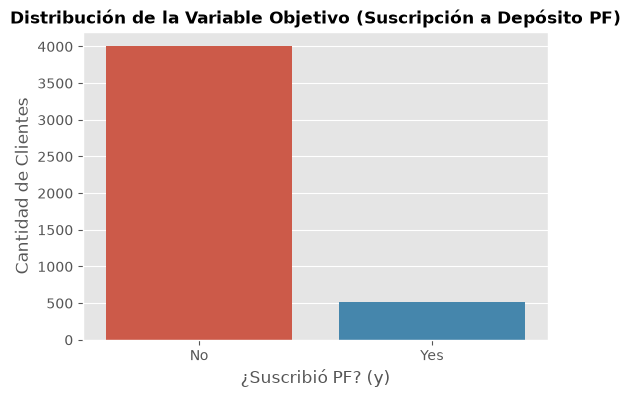

In [7]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='y', hue='y', legend=False)
plt.title('Distribución de la Variable Objetivo (Suscripción a Depósito PF)', fontsize=12, fontweight='bold')
plt.xlabel('¿Suscribió PF? (y)')
plt.ylabel('Cantidad de Clientes')
plt.xticks([0, 1], ['No', 'Yes'])
plt.show()

El dataset presenta un desbalance entre las clases: 4.000 clientes (88,48 %) no aceptaron la oferta y 521 (11,52 %) sí la aceptaron.
Esta diferencia puede afectar el desempeño de los modelos de clasificación.
Un valor de accuracy elevado no garantiza una correcta identificación de los clientes que aceptan.
Por ello, se priorizará el Recall de la clase 'yes', para medir cuántos clientes interesados identifica el modelo.
También se evaluarán elvalor de precision y la matriz de confusión para analizar los errores de clasificación.

# Histogramas y Boxplots para observar la distribución y detectar posibles outliers.

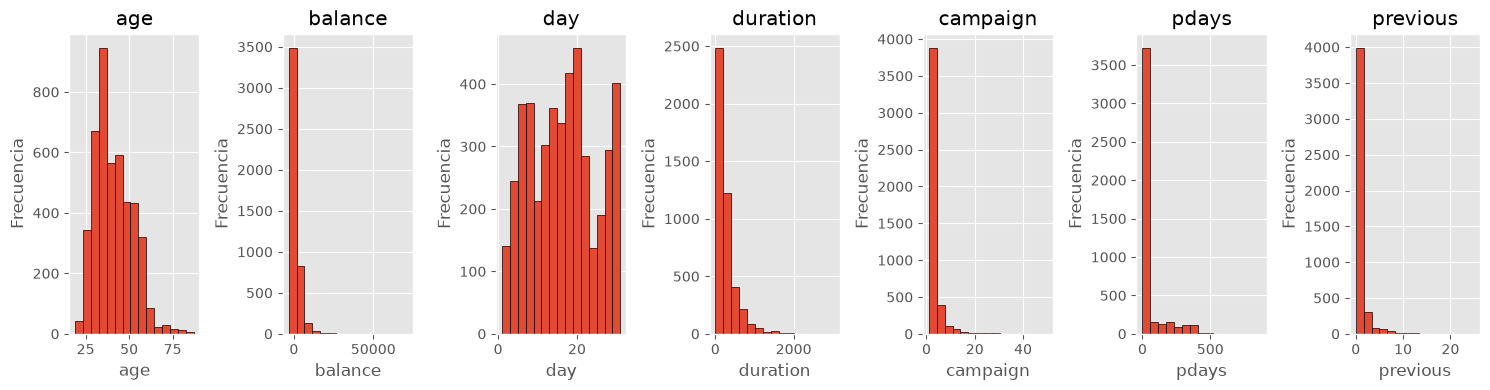

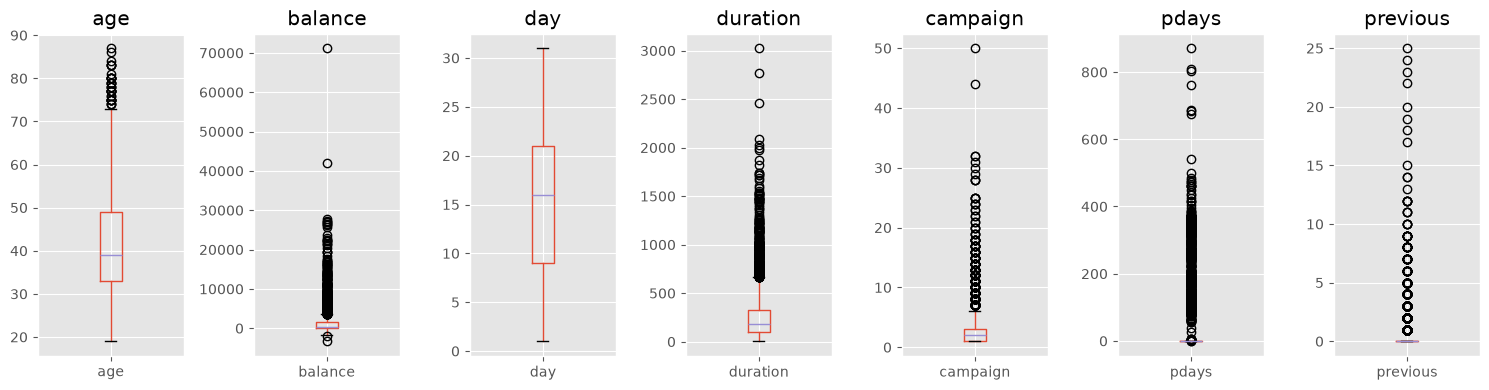

In [8]:
# Seleccionamos las columnas numéricas
#numericas = df.select_dtypes(include=[np.number]).columns
numericas = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]

# Histogramas
fig, axes = plt.subplots(1, 7, figsize=(15, 4))

for ax, columna in zip(axes, numericas):
    df[columna].hist(bins=15, ax=ax, edgecolor="black")
    ax.set_title(f"{columna}")
    ax.set_xlabel(columna)
    ax.set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

# Boxplots
fig, axes = plt.subplots(1, 7, figsize=(15, 4))

for ax, columna in zip(axes, numericas):
    df.boxplot(column=columna, ax=ax)
    ax.set_title(f"{columna}")

plt.tight_layout()
plt.show()

In [9]:
# Seleccionar solo columnas numéricas
numericas = df.select_dtypes(include=[np.number]).columns

for col in numericas:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lim_inf) | (df[col] > lim_sup)]
    if len(outliers) > 0:
        print(f"Variable '{col}': {len(outliers)} porcentaje de outliers ({round(len(outliers)/len(df)*100, 2)}%)")

Variable 'age': 38 porcentaje de outliers (0.84%)
Variable 'balance': 506 porcentaje de outliers (11.19%)
Variable 'duration': 330 porcentaje de outliers (7.3%)
Variable 'campaign': 318 porcentaje de outliers (7.03%)
Variable 'pdays': 816 porcentaje de outliers (18.05%)
Variable 'previous': 816 porcentaje de outliers (18.05%)


Analizaando los gráficos del dataset, la gran mayoría de estos valores corresponden a comportamiento real de los clientes y no deben eliminarse de forma arbitraria representan información válida e importante para el modelo. 
Age (0,84%) corresponde a clientes mayores; balance (11,19%), a saldos bancarios extremos; y duration (7,30%) y campaign (7,03%), a llamadas largas o contactos frecuentes. Por su parte, pdays y previous (18,05%) identifican clientes sin contactos previos. 
En todos los casos, conviene conservar los registros y evaluar su significado antes de aplicar cualquier tratamiento.

Para el caso de modelo de Árbol de Decisión, los valores extremos no representan un problema grave. Como el árbol evalúa condiciones por umbrales en cada columna (por ejemplo, ¿balance > 5000?), no calcula medias ni distancias geométricas, por lo que la magnitud de los valores más lejanos no distorsiona las decisiones de corte.



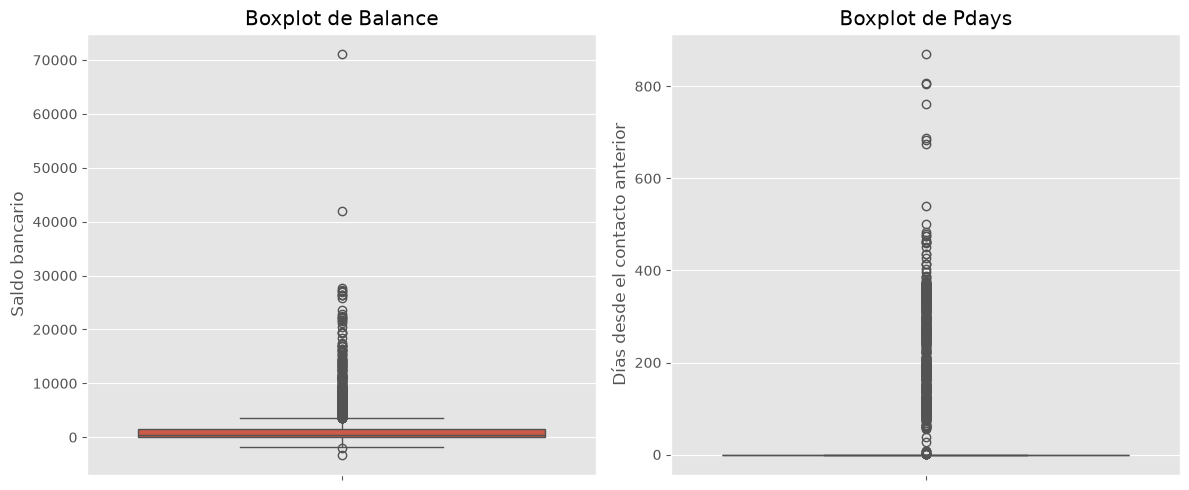

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Boxplot de balance
sns.boxplot(y=df['balance'], ax=axs[0])
axs[0].set_title('Boxplot de Balance')
axs[0].set_ylabel('Saldo bancario')

# Boxplot de pdays
sns.boxplot(y=df['pdays'], ax=axs[1])
axs[1].set_title('Boxplot de Pdays')
axs[1].set_ylabel('Días desde el contacto anterior')

plt.tight_layout()
plt.show()

La variable 'balance', permite identificar saldos bancarios extremos. Los puntos fuera de los bigotes son posibles valores atípicos, pero pueden ser datos válidos.

La variable 'pdays', muestra valores en -1, que indican clientes que no fueron contactados en campañas anteriores. Es un valor especial con significado propio, no necesariamente un dato atípico que deba eliminarse.

# Preprocesamiento de Variables

No se utuliza la variable 'duration' (duración de la llamada) ya que el objetivo es predecir, antes de contactar al cliente, si aceptará la oferta. 
Esa variable solo se conoce durante o después de la llamada.

Se separa las variables predictoras (X) de la variable objetivo (y), se identifica las columnas numéricas y categóricas y luego se divide los datos en un 80 % para entrenamiento y 20 % para prueba, manteniendo la proporción de clases.
Se construye un preprocesador que completa valores faltantes, estandariza las variables numéricas y codifica las categóricas mediante One-Hot Encoder. Finalmente, ajusta el preprocesamiento solo con los datos de entrenamiento y lo aplica a ambos conjuntos, evitando la fuga de información (data leakage).
Aplicamos RobustScaler, que usa la mediana y el rango intercuartílico. Esto evita que los valores extremos distorsionen la escala, algo crítico para el SVM, que depende de distancias geométricas.

In [11]:
# Separar variables predictoras (X) y variable objetivo (y)
X = df.drop(columns=['y', 'duration'])
y = df['y'].map({'yes': 1, 'no': 0})  # Codificación binaria

columnas_numericas = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
columnas_categoricas = X.select_dtypes(include=['object', 'str']).columns.tolist()

# Construcción del Pipeline con RobustScaler
# 1. Numéricas: Imputación por mediana + RobustScaler (resistente a outliers)
pipeline_num = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())])

# 2. Categóricas: Imputación por moda + OneHotEncoder
pipeline_cat = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

# Unir transformadores en el ColumnTransformer
preprocesador = ColumnTransformer([
    ('num', pipeline_num, columnas_numericas),
    ('cat', pipeline_cat, columnas_categoricas)])

# Separación Train / Test con estratificación
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

print(f"\nMuestras de Entrenamiento: {len(X_train)} | Muestras de Prueba: {len(X_test)}")
print("\nDistribución en entrenamiento:")
print(y_train.value_counts())

print("\nDistribución en prueba:")
print(y_test.value_counts())

# Ajustar solo en Train y transformar ambos conjuntos (Evita Data Leakage)
X_train_prep = preprocesador.fit_transform(X_train)
X_test_prep = preprocesador.transform(X_test)

print("¡Preprocesamiento completado con RobustScaler!")
print(f"Dimensiones de la matriz de entrenamiento: {X_train_prep.shape}")


Muestras de Entrenamiento: 3616 | Muestras de Prueba: 905

Distribución en entrenamiento:
y
0    3199
1     417
Name: count, dtype: int64

Distribución en prueba:
y
0    801
1    104
Name: count, dtype: int64
¡Preprocesamiento completado con RobustScaler!
Dimensiones de la matriz de entrenamiento: (3616, 50)


# Modelo SVC y Árbol de Decisión
Support Vector Classifier (SVC): es un algoritmo de aprendizaje supervisado utilizado para resolver problemas de clasificación. Su funcionamiento consiste en encontrar una frontera de separación, denominada hiperplano, que permita distinguir las diferentes clases de datos. Para ello, busca maximizar la distancia entre esa frontera y los ejemplos más próximos de cada clase, llamados vectores de soporte. De esta manera, procura lograr una clasificación precisa y una buena capacidad de generalización ante nuevos datos.

Árbol de Decisión: es un algoritmo de aprendizaje supervisado que permite clasificar datos mediante una estructura de decisiones organizada en forma de árbol. Su funcionamiento consiste en dividir los datos en grupos a partir de condiciones aplicadas sobre las variables predictoras. Cada división busca separar las clases de la mejor manera posible, mientras que las hojas representan la clase final asignada a cada registro. En este trabajo, se utilizó un árbol con una profundidad máxima de 4 niveles (Max Depth = 4), lo que limita su complejidad y puede ayudar a reducir el sobreajuste. Además, su estructura facilita la interpretación de las reglas utilizadas para realizar las predicciones.

In [12]:
# --- Modelo 1: Support Vector Machine (SVM) ---
print("Entrenando Modelo 1: Support Vector Machine (SVC)...")
modelo_svm = SVC(kernel='rbf', C=1.0, random_state=42)
modelo_svm.fit(X_train_prep, y_train)
pred_svm = modelo_svm.predict(X_test_prep)
print("¡SVM entrenado correctamente!")

# --- Modelo 2: Árbol de Decisión (Decision Tree) ---
print("\nEntrenando Modelo 2: Decision Tree Classifier...")
modelo_arbol = DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42)
modelo_arbol.fit(X_train_prep, y_train)
pred_arbol = modelo_arbol.predict(X_test_prep)
print("¡Árbol de Decisión entrenado correctamente!")

Entrenando Modelo 1: Support Vector Machine (SVC)...
¡SVM entrenado correctamente!

Entrenando Modelo 2: Decision Tree Classifier...
¡Árbol de Decisión entrenado correctamente!


# Comparación de los modelos
Se evalúa y compara el rendimiento de los modelos SVM y Árbol de Decisión. 
Primero, genera y muestra sus matrices de confusión para identificar aciertos y errores de clasificación. Luego, presenta los reportes detallados con las métricas de precisión, recall y F1-score para cada clase. Finalmente, construye un cuadro comparativo con las métricas principales —accuracy, precisión, recall y F1-score— para determinar cuál de los dos modelos obtuvo mejores resultados.

Matriz de Confusión - Support Vector Machine
[[799   2]
 [104   0]]

Matriz de Confusión - Árbol de Decisión
[[766  35]
 [ 75  29]]


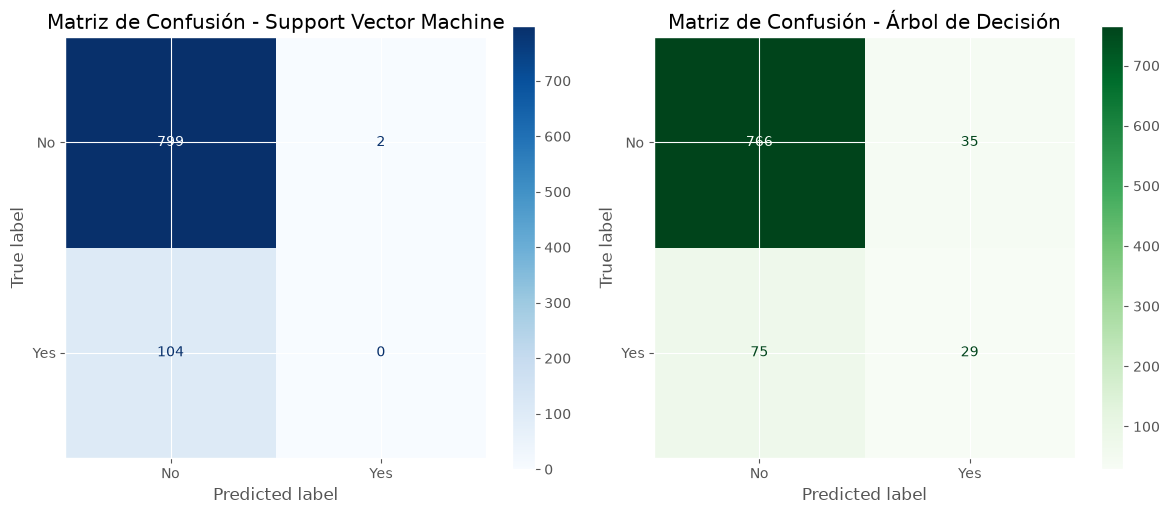

REPORTE DE CLASIFICACIÓN: SUPPORT VECTOR MACHINE (SVM)
              precision    recall  f1-score   support

      No (0)       0.88      1.00      0.94       801
     Yes (1)       0.00      0.00      0.00       104

    accuracy                           0.88       905
   macro avg       0.44      0.50      0.47       905
weighted avg       0.78      0.88      0.83       905

REPORTE DE CLASIFICACIÓN: ÁRBOL DE DECISIÓN
              precision    recall  f1-score   support

      No (0)       0.91      0.96      0.93       801
     Yes (1)       0.45      0.28      0.35       104

    accuracy                           0.88       905
   macro avg       0.68      0.62      0.64       905
weighted avg       0.86      0.88      0.87       905


--- CUADRO COMPARATIVO FINAL DE MÉTRICAS ---


Modelo,Accuracy,Precisión,Recall,F1-Score
Support Vector Machine (SVM),0.882900,0.000000,0.000000,0.000000
Árbol de Decisión (Max Depth=4),0.878500,0.453100,0.278800,0.345200


In [13]:
# A. MATRICES DE CONFUSIÓN
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Matriz SVM
cm_svm = confusion_matrix(y_test, pred_svm)
disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=['No', 'Yes'])
disp_svm.plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Matriz de Confusión - Support Vector Machine')

print("Matriz de Confusión - Support Vector Machine")
print(cm_svm)

# Matriz Árbol de Decisión
cm_arbol = confusion_matrix(y_test, pred_arbol)
disp_arbol = ConfusionMatrixDisplay(confusion_matrix=cm_arbol, display_labels=['No', 'Yes'])
disp_arbol.plot(ax=axes[1], cmap='Greens')
axes[1].set_title('Matriz de Confusión - Árbol de Decisión')

print("\nMatriz de Confusión - Árbol de Decisión")
print(cm_arbol)

plt.tight_layout()
plt.show()

# B. REPORTES DE CLASIFICACIÓN DETALLADOS
print("=" * 60)
print("REPORTE DE CLASIFICACIÓN: SUPPORT VECTOR MACHINE (SVM)")
print("=" * 60)

print(classification_report(y_test, pred_svm, target_names=['No (0)', 'Yes (1)'], zero_division=0))

print("=" * 60)
print("REPORTE DE CLASIFICACIÓN: ÁRBOL DE DECISIÓN")
print("=" * 60)

print(classification_report(y_test, pred_arbol, target_names=['No (0)', 'Yes (1)'], zero_division=0))

# C. CUADRO COMPARATIVO FINAL DE MÉTRICAS
cuadro_comparativo = pd.DataFrame({
    'Modelo': [
        'Support Vector Machine (SVM)',
        'Árbol de Decisión (Max Depth=4)'
    ],
    'Accuracy': [
        accuracy_score(y_test, pred_svm),
        accuracy_score(y_test, pred_arbol)
    ],
    'Precisión': [
    precision_score(y_test, pred_svm, zero_division=0),
    precision_score(y_test, pred_arbol, zero_division=0)
    ],
    'Recall': [
    recall_score(y_test, pred_svm, zero_division=0),
    recall_score(y_test, pred_arbol, zero_division=0)
    ],
    'F1-Score': [
    f1_score(y_test, pred_svm, zero_division=0),
    f1_score(y_test, pred_arbol, zero_division=0)
    ]
})

print("\n--- CUADRO COMPARATIVO FINAL DE MÉTRICAS ---")
display(cuadro_comparativo.round(4).style.hide(axis="index"))

El Árbol de Decisión tiene un mejor desempeño que el SVM para identificar a los clientes que aceptan la oferta bancaria.

Aunque ambos modelos presentan una exactitud (Accuracy) similar, cercana al 88 %, el SVM tiene precisión, recall y F1-Score iguales a cero, lo que indica que no logró identificar correctamente ningún cliente de la clase positiva (yes). Esto puede deberse a que predice todos los casos como no, debido al desbalance de clases.

En cambio, el Árbol de Decisión alcanza una precisión del 45,31 % y un recall del 27,88 %, por lo que logra identificar algunos clientes interesados, aunque todavía deja sin detectar a muchos.

El Árbol de Decisión es la mejor alternativa entre ambos resultados, pero es necesario mejorar los modelos para detectar más clientes que aceptarían la oferta. Se recomienda probar el balanceo de clases y ajustar los hiperparámetros, priorizando el recall y el F1-Score de la clase yes.


# Visualización del Árbol de Desición

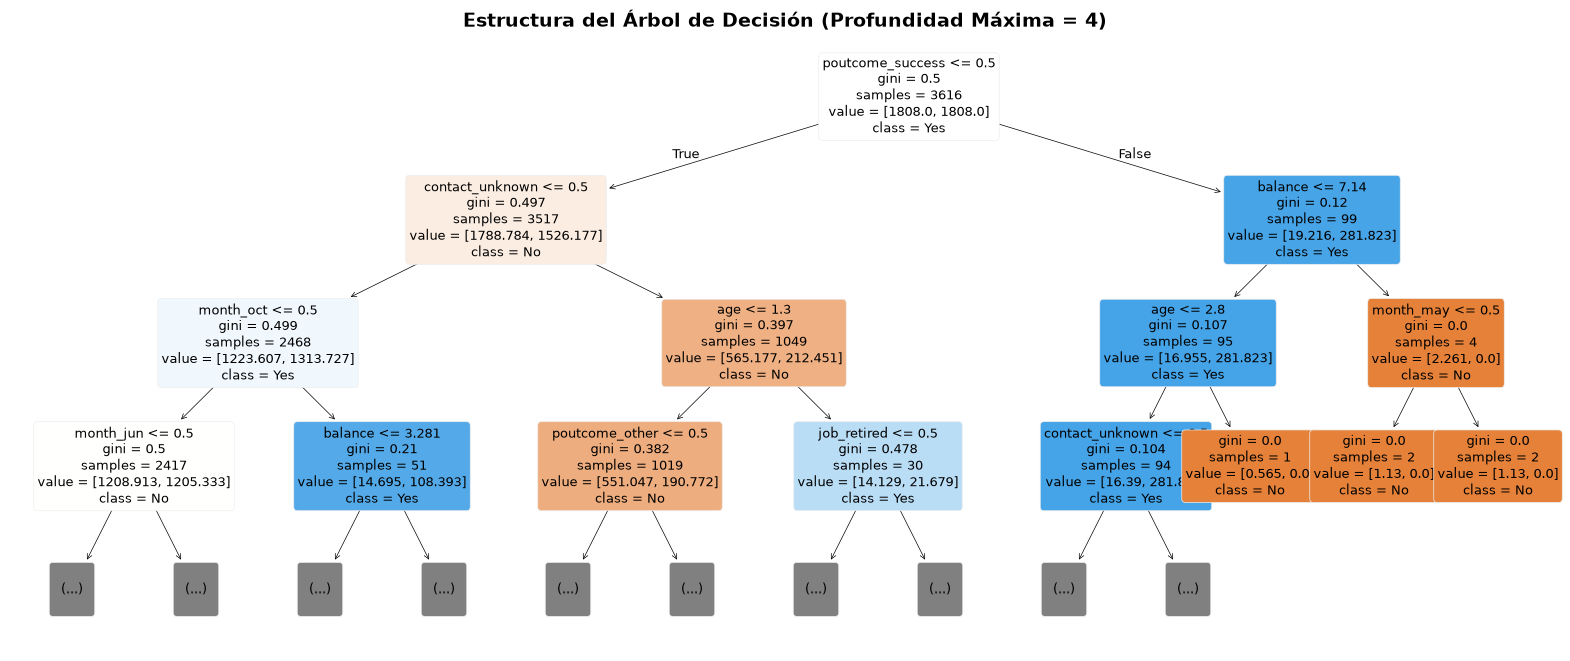

In [14]:
# Obtener nombres de columnas codificadas para el gráfico del árbol
cat_encoder = preprocesador.named_transformers_['cat'].named_steps['onehot']
cat_cols_encoded = cat_encoder.get_feature_names_out(columnas_categoricas).tolist()
nombres_caracteristicas = columnas_numericas + cat_cols_encoded

plt.figure(figsize=(20, 8))
plot_tree(modelo_arbol, feature_names=nombres_caracteristicas, 
    class_names=['No', 'Yes'], filled=True, rounded=True, max_depth=3,fontsize=9)
plt.title("Estructura del Árbol de Decisión (Profundidad Máxima = 4)", fontsize=14, fontweight='bold')
plt.show()


# Conclusión

El presente trabajo permitió comparar el desempeño de dos algoritmos de clasificación supervisada —Support Vector Machine y Árbol de Decisión— sobre el dataset Bank Marketing, con el objetivo de identificar clientes potenciales para la suscripción de un depósito a plazo fijo. 

Los resultados evidencian que, ante un fuerte desbalance de clases (88,48 % vs. 11,52 %), el accuracy no es una métrica suficiente para evaluar el rendimiento de un modelo. Mientras que el SVM alcanzó un accuracy cercano al 88 % pero fue incapaz de detectar un solo cliente de la clase positiva, el Árbol de Decisión, con una exactitud ligeramente inferior, logró identificar parte de los clientes interesados (recall = 27,88 %, F1 = 34,52 %).

En conclusión, el Árbol de Decisión es el modelo más adecuado, gracias a su capacidad de generar reglas de corte sobre las variables y al uso de class_weight="balanced", logra un desempeño funcionalmente superior al SVM, que colapsa hacia la clase mayoritaria. 

Como trabajo futuro se recomienda aplicar técnicas de balanceo de clases (SMOTE, class_weight), optimizar hiperparámetros mediante búsqueda sistemática, ajustar el umbral de decisión con curvas Precision-Recall, e incorporar el uso de Random Forest o Gradient Boosting, priorizando siempre el recall y el F1-score de la clase minoritaria por su mayor impacto en el objetivo.